
# Model 11: Interacting Neurons

## Objective

Construct a network of interconnected neurons whose activities influence one another through weighted synaptic connections.

Unlike previous models, which focused on individual synaptic weights, this model investigates how neural activity propagates through a network.

## Research Questions

1. How does activating one neuron influence the activity of others?
2. How do excitatory and inhibitory connections affect network behavior?
3. Can patterns of neural activity emerge from local interactions?

## Hypothesis

Stimulating one neuron will cause activity to propagate through excitatory connections, while inhibitory connections will suppress the activation of certain neurons.

## Model Assumptions

- Neurons have binary activity states: 0 (inactive) or 1 (active).
- Connections between neurons have fixed synaptic weights.
- Positive weights represent excitatory connections.
- Negative weights represent inhibitory connections.
- A neuron activates when its total input reaches a threshold.
- All neurons update their states simultaneously.

This model focuses on neural interactions rather than learning. Synaptic weight updates will be introduced in future models.


In [9]:

import numpy as np
import matplotlib.pyplot as plt

num_neurons = 6
threshold = 1.0

# Initialize the weight matrix
W = np.zeros((num_neurons, num_neurons))

# Excitatory connections
W[1, 0] = 1.2  # Neuron 1 -> 2
W[2, 1] = 1.1  # Neuron 2 -> 3
W[3, 2] = 1.2  # Neuron 3 -> 4
W[4, 1] = 1.1  # Neuron 2 -> 5
W[5, 2] = 1.1  # Neuron 3 -> 6

# Inhibitory connection
W[4, 3] = -1.5 # Neuron 4 inhibits neuron 5

# Feedback connections
W[2, 3] = 0.25 # Neuron 4 -> 3
W[1, 5] = 0.2  # Neuron 6 -> 2

# External stimulation to neuron 1
bias = np.array([1.2, 0, 0, 0, 0, 0])

print(W)


[[ 0.    0.    0.    0.    0.    0.  ]
 [ 1.2   0.    0.    0.    0.    0.2 ]
 [ 0.    1.1   0.    0.25  0.    0.  ]
 [ 0.    0.    1.2   0.    0.    0.  ]
 [ 0.    1.1   0.   -1.5   0.    0.  ]
 [ 0.    0.    1.1   0.    0.    0.  ]]


In [10]:

def update_neurons(activities, W, bias, threshold):
    inputs = W @ activities + bias

    return (inputs >= threshold).astype(int)


In [11]:

steps = 10

activities = np.array([1, 0, 0, 0, 0, 0])

history = [activities.copy()]

for t in range(steps):
    activities = update_neurons(
        activities, W, bias, threshold
    )

    history.append(activities.copy())

history = np.array(history)

print(history)


[[1 0 0 0 0 0]
 [1 1 0 0 0 0]
 [1 1 1 0 1 0]
 [1 1 1 1 1 1]
 [1 1 1 1 0 1]
 [1 1 1 1 0 1]
 [1 1 1 1 0 1]
 [1 1 1 1 0 1]
 [1 1 1 1 0 1]
 [1 1 1 1 0 1]
 [1 1 1 1 0 1]]


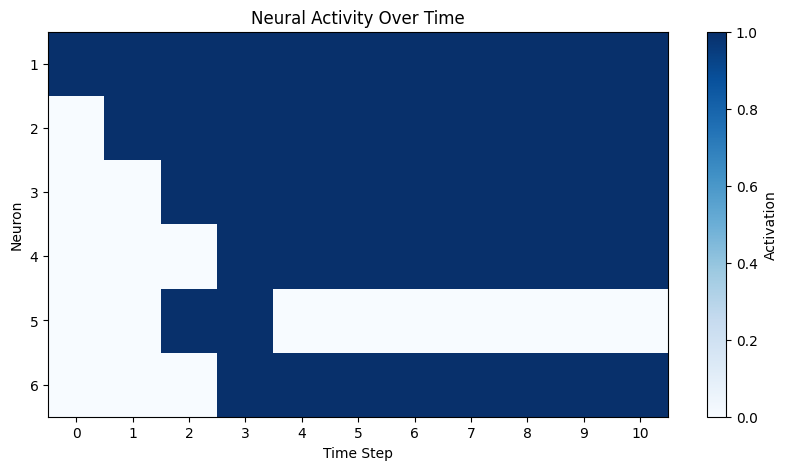

In [12]:

plt.figure(figsize=(10, 5))

plt.imshow(
    history.T,
    cmap="Blues",
    aspect="auto",
    vmin=0,
    vmax=1
)

plt.xlabel("Time Step")
plt.ylabel("Neuron")
plt.title("Neural Activity Over Time")

plt.xticks(range(steps + 1))
plt.yticks(range(num_neurons),
           range(1, num_neurons + 1))

plt.colorbar(label="Activation")
plt.show()


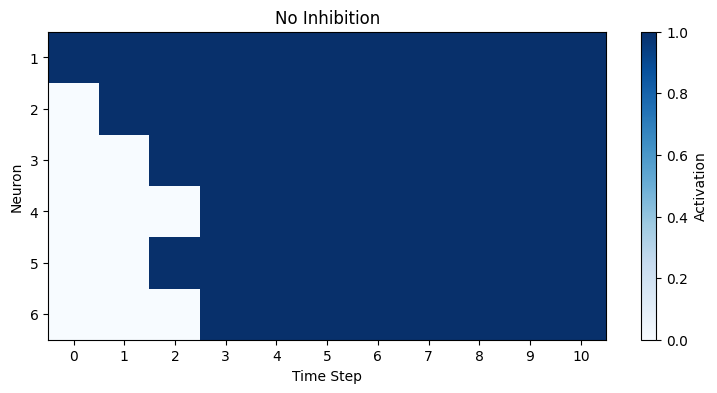

No Inhibition final state: [1 1 1 1 1 1]


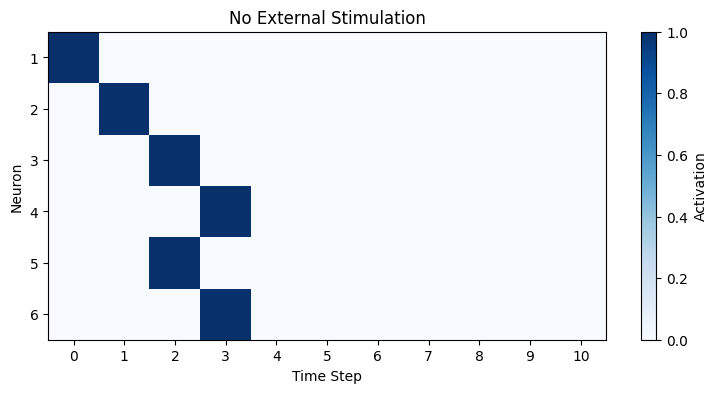

No External Stimulation final state: [0 0 0 0 0 0]


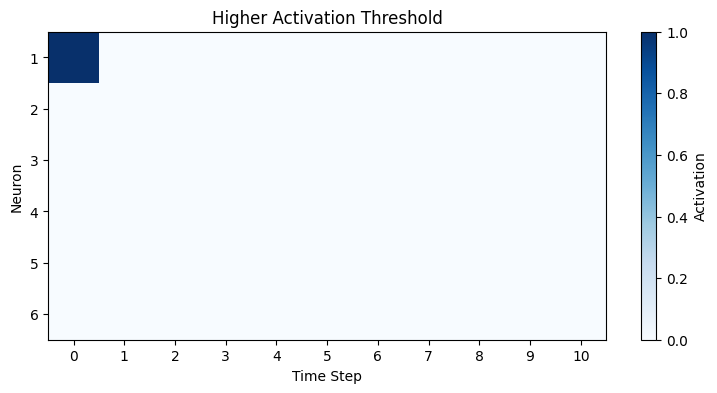

Higher Activation Threshold final state: [0 0 0 0 0 0]


In [13]:

def simulate_network(W, bias, threshold, steps=10):
    activities = np.array([1, 0, 0, 0, 0, 0])
    history = [activities.copy()]

    for t in range(steps):
        activities = update_neurons(
            activities, W, bias, threshold
        )
        history.append(activities.copy())

    return np.array(history)


# Experiment 1: Remove inhibition
W_no_inhibition = W.copy()
W_no_inhibition[4, 3] = 0

# Experiment 2: Remove continuous stimulation
bias_no_stimulation = np.zeros(num_neurons)

# Experiment 3: Increase activation threshold
higher_threshold = 1.3

experiments = {
    "No Inhibition": (W_no_inhibition, bias, threshold),
    "No External Stimulation": (W, bias_no_stimulation, threshold),
    "Higher Activation Threshold": (W, bias, higher_threshold)
}

for name, (weights, external_input, theta) in experiments.items():
    result = simulate_network(weights, external_input, theta)

    plt.figure(figsize=(9, 4))
    plt.imshow(result.T, cmap="Blues", aspect="auto",
               vmin=0, vmax=1)

    plt.title(name)
    plt.xlabel("Time Step")
    plt.ylabel("Neuron")
    plt.xticks(range(result.shape[0]))
    plt.yticks(range(num_neurons), range(1, num_neurons + 1))
    plt.colorbar(label="Activation")
    plt.show()

    print(f"{name} final state: {result[-1]}")


## Experimental Results and Discussion

### Experiment 1: No Inhibition
Without the inhibitory connection from neuron 4 to neuron 5, all six neurons eventually become active and remain active. Previously, neuron 4 suppressed neuron 5 despite the excitatory input it received from neuron 2. Removing this inhibition allows neuron 5 to maintain its activity, demonstrating how inhibitory connections regulate neural activity patterns.

### Experiment 2: No External Stimulation
Without continuous external stimulation, neural activity initially propagates through the network but eventually disappears. Although neuron 1 is initially active, it becomes inactive without sustained input. The remaining neurons activate temporarily through their connections, but the network cannot maintain activity indefinitely. This demonstrates that the current network cannot sustain persistent activation without external stimulation.

### Experiment 3: Higher Activation Threshold
Increasing the activation threshold from 1.0 to 1.3 prevents activity from propagating through the network. The existing excitatory connections are insufficient to activate neighboring neurons, and the external stimulation of 1.2 is no longer enough to sustain neuron 1. Consequently, all neurons become inactive after the first update.

### Conclusion
These experiments demonstrate how neural activity depends on the balance between excitation, inhibition, external stimulation, and activation thresholds. They also highlight a limitation of the current model: synaptic weights remain fixed, preventing the network from adapting its connections through experience. Future models will introduce activity-dependent learning to investigate how neural networks can develop and maintain learned patterns.


## Limitations and Future Directions

### Limitations

- **Fixed synaptic weights:** Connections cannot strengthen or weaken through experience, preventing the network from learning.
- **Binary activation:** Neurons are either fully active or inactive, simplifying the continuous and complex nature of biological neural activity.
- **Small network size:** The six-neuron network demonstrates basic interactions but cannot represent complex memory patterns.
- **Simplified network dynamics:** All neurons update simultaneously using fixed thresholds, without delays, noise, or more realistic biological mechanisms.
- **Dependence on external stimulation:** With the current connections, neural activity cannot persist without continuous external input.

### Future Directions

Future models will introduce activity-dependent synaptic plasticity through Hebbian learning, allowing connections to strengthen when neurons activate together.

Eventually, we will investigate whether learned connections can support persistent activity, store distributed memory patterns, and reproduce forgetting through synaptic decay.
